In [ ]:
from matplotlib import pyplot as plt
import json
import numpy as np
import networkx as nx

In [2]:
def plot_scatter(filename, attr1, attr2, attr3=None, fig=None, **kwargs):
    with open(filename) as f:
        data = json.load(f)
    if fig:
        fig = plt.figure(fig)
    else:
        fig = plt.figure()
    samples = data["samples"]

    attr1_mapping = kwargs.get("attr1_mapping", lambda x: x)
    attr2_mapping = kwargs.get("attr2_mapping", lambda x: x)
    attr3_mapping = kwargs.get("attr3_mapping", lambda x: x)

    if attr1 in samples[0]["graph_info"]:
        attr1_values = np.array([attr1_mapping(s["graph_info"][attr1]) for s in samples])
    else:
        attr1_values = np.array([attr1_mapping(s[attr1]) for s in samples])

    if attr2 in samples[0]["graph_info"]:
        attr2_values = np.array([attr2_mapping(s["graph_info"][attr2]) for s in samples])
    else:
        attr2_values = np.array([attr2_mapping(s[attr2]) for s in samples])

    if attr3:
        if attr2 in samples[0]["graph_info"]:
            attr3_values = np.array([attr3_mapping(s["graph_info"][attr3]) for s in samples])
        else:
            attr3_values = np.array([attr3_mapping(s[attr3]) for s in samples])

    if attr3:
        c = attr3_values
    else:
        c = kwargs.get("color", None)

    if "xlim" in kwargs:
        plt.xlim(kwargs.get("xlim", None))

    if "ylim" in kwargs:
            plt.ylim(kwargs.get("ylim", None))

    if "cmap_range" in kwargs:
        vmin = kwargs.get("cmap_range")[0]
        vmax = kwargs.get("cmap_range")[1]
    else:
        vmin=None
        vmax=None
    plt.xlabel(attr1)
    plt.ylabel(attr2)
    scatter = plt.scatter(attr1_values, attr2_values, alpha=kwargs.get("alpha", 1), c=c, cmap="viridis", vmin=vmin, vmax=vmax)
    if attr3:
        plt.colorbar(scatter, label=attr3)
    plt.show()
    return fig

In [3]:
def plot_graph_info(filename, plot, attribute, fig=None, **kwargs):
    with open(filename) as f:
        data = json.load(f)
    if fig:
        fig = plt.figure(fig)
    else:
        fig = plt.figure()
    samples = data["samples"]
    # print(f"Average probability: {np.mean(probs)}")
    # print(f"Average min gap size: {np.mean(gaps)}")

    if "xlim" in kwargs:
        plt.xlim(kwargs.get("xlim", None))

    plt.xscale(kwargs.get("xscale", "linear"))
    attribute_mapping = kwargs.get("attribute_mapping", lambda x: x)

    plt.xlabel(attribute)

    if plot == "hist":
        attribute_values = np.array([s["graph_info"][attribute] for s in samples])
        plt.ylabel("counts")
        plt.hist(attribute_values, kwargs.get("bins", 10), density=True, color=kwargs.get("color", "tab:blue"), alpha=0.6, label=kwargs.get("label", None))

    elif plot == "bar violin":
        plt.ylabel(attribute)
        # current_tick_x, current_tick_text = plt.xticks()
        # current_tick_x = current_tick_x.tolist()
        # current_tick_x.append(kwargs.get("column", 0))
        # current_tick_text.append(kwargs.get("label", attribute))
        # print(plt.xticks())
        # plt.xticks(current_tick_x, current_tick_text)
        column = kwargs.get("column", 0)
        if attribute in samples[0]["graph_info"]:
            attribute_values = np.array([attribute_mapping(s["graph_info"][attribute]) for s in samples])
        else:
            attribute_values = np.array([attribute_mapping(s[attribute]) for s in samples])
        attribute_mean = np.mean(attribute_values)
        violin_parts = plt.gca().violinplot(attribute_values, [column], showmeans=True)
        for pc in violin_parts['bodies']:
            pc.set_color(kwargs.get("color", "tab:blue"))
        # plt.hlines(attribute_mean, column-0.3, column+0.3, colors=kwargs.get("color", "tab:blue"))
    # plt.show()

    if kwargs.get("legend", False):
        plt.legend()
    plt.show()
    return fig

In [4]:
def plot_annealing(filename, plot, fig=None, **kwargs):
    with open(filename) as f:
        data = json.load(f)
    if fig:
        fig = plt.figure(fig)
    else:
        fig = plt.figure()
    samples = data["samples"]
    gaps = np.array([s["min_gap"] for s in samples])
    probs = np.array([s["prob"] for s in samples])

    print(f"Average probability: {np.mean(probs)}")
    print(f"Average min gap size: {np.mean(gaps)}")

    if "xlim" in kwargs:
        plt.xlim(kwargs.get("xlim", None))

    plt.xscale(kwargs.get("xscale", "linear"))
    if plot == "gap vs prob":
        plt.xlabel("Min gap")
        plt.ylabel("Success probability")
        plt.scatter(gaps, probs, color=kwargs.get("color", "tab:blue"), alpha=0.6, s=8, label=kwargs.get("label", None))
        # plt.show()
    elif plot == "gap hist":
        # plt.figure()
        plt.xlabel("Min gap")
        plt.ylabel("Counts")
        plt.hist(gaps, kwargs.get("bins", 20), density=True, color=kwargs.get("color", "tab:blue"), alpha=0.6, label=kwargs.get("label", None))

    if kwargs.get("legend", False):
        plt.legend()
    plt.show()
    return fig

{'min_gap': 0.015622033984364486, 'min_gap_position_t': 0.6868686868686869, 'prob': 0.7057393385914703, 'graph_info': {'number_of_nodes': 10, 'number_of_edges': 31, 'max_clique_size': 6, 'max_clique_count': 1, 'smaller_clique_counts': [9, 28]}, 'eigenenergies': [[-0.41666666666666763, -0.33333333333333476, -0.3333333333333335, -0.3333333333333329, -0.25000000000000017, -0.24999999999999997], [-0.4146571313062171, -0.33189263283677467, -0.3318228477182275, -0.3317489630712931, -0.33170270204222563, -0.3316586835419798], [-0.41206528410956933, -0.33003458097183475, -0.3298729824553347, -0.3297061855116293, -0.32960044133714683, -0.3294987154134406], [-0.4092091242870209, -0.32798739729850973, -0.327722094377905, -0.3274560939385976, -0.3272850318562697, -0.3271185447564549], [-0.4061758951262147, -0.3258139376396298, -0.32543538655404364, -0.32506777629915173, -0.32482760281037915, -0.32459106083779243], [-0.4030115346874614, -0.32354749718765746, -0.3230471493173951, -0.3225777365139171

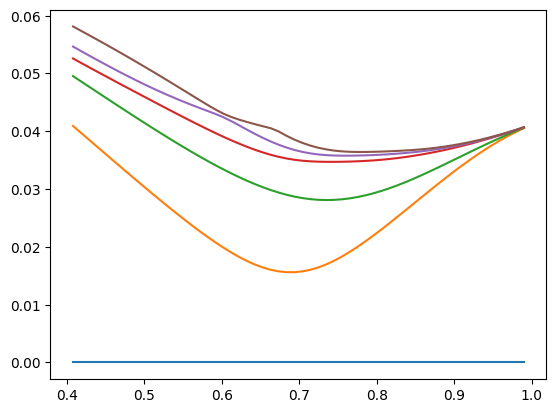

In [5]:
# nrows = int(np.ceil(np.sqrt(len(energies))))
# ncols = int(np.ceil(len(energies)/nrows))
# print(nrows, ncols)
# fig, ax = plt.subplots(nrows, ncols, squeeze=False)
# with open("benchmarkResults/energies/qa_energies_results_maxclique_er_n10_p05.json", "r") as f:
with open("benchmarkResults/energies/qa_energies_results_maxclique_clas_hard_n10_p05_3.json", "r") as f:
    data = json.load(f)
index = 0
print(data["samples"][index])
energies = np.array(data["samples"][index]["eigenenergies"])
energies = energies - np.reshape(energies[:,0], (len(energies), 1))
from_ti = 40
to_ti = -1
for j in range(len(energies[0])):
    plt.plot(np.linspace(0, 1, len(energies))[from_ti:to_ti], energies[from_ti:to_ti,j])
plt.plot()
plt.show()

qa maxclique, different n


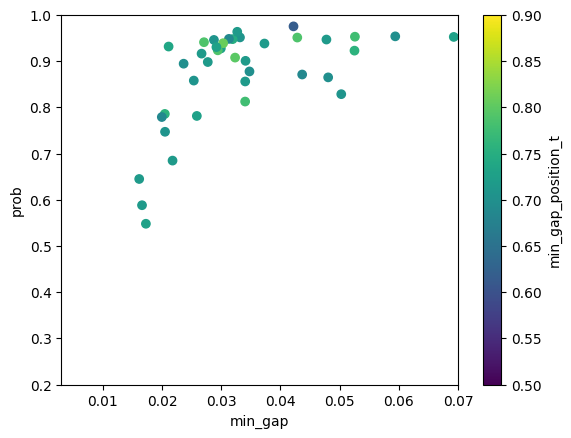

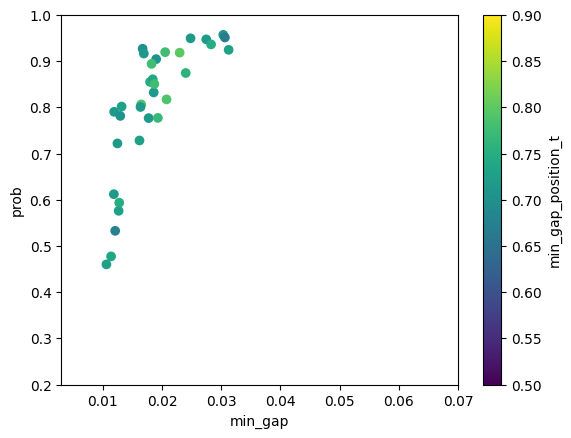

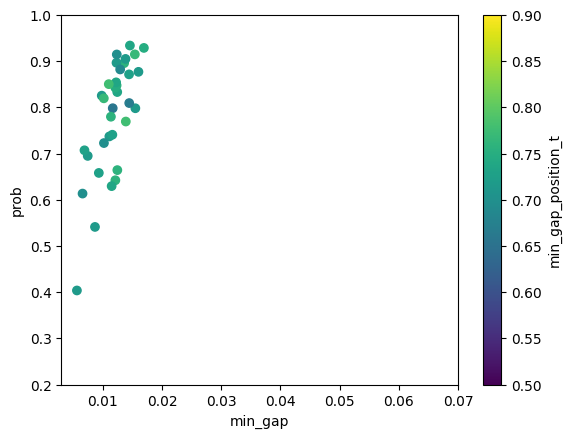

In [74]:
ns = [8, 10, 12]
for i in range(len(ns)):
    fig = plot_scatter(f"benchmarkResults/energies/qa_energies_results_maxclique_er_n{ns[i]}_p06.json", 
                    attr1="min_gap", 
                    attr2="prob", 
                    attr3="min_gap_position_t", 
                    color="tab:red", 
                    label="ER", 
                    alpha=1, 
                    cmap_range=(0.5, 0.9), 
                    xlim=(0.003, 0.07), 
                    ylim=(0.2, 1)
                    # attr1="min_gap_position_t", 
                    # attr2="min_gap", 
                    # attr3="prob", 
                    # alpha=0.6, 
                    # cmap_range=(0.2, 1), 
                    # xlim=(0.5, 0.95), 
                    # ylim=(0.001, 0.11)
                )

qa maxclique, different p

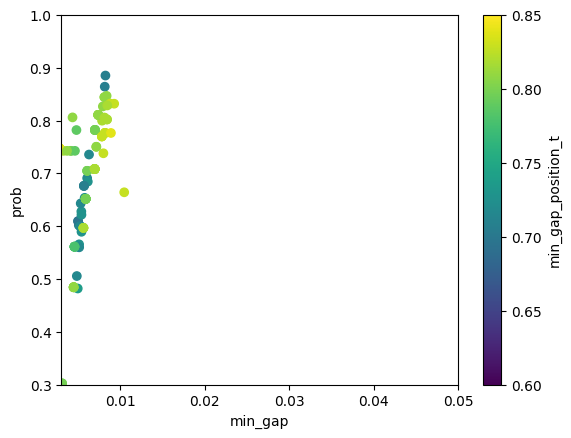

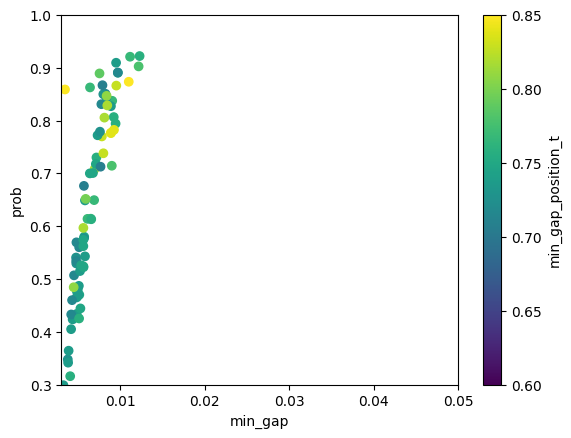

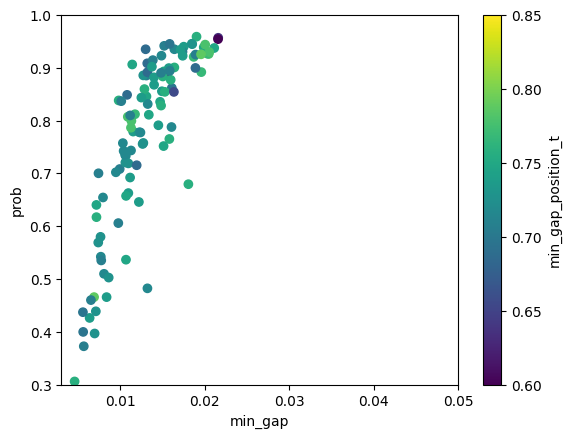

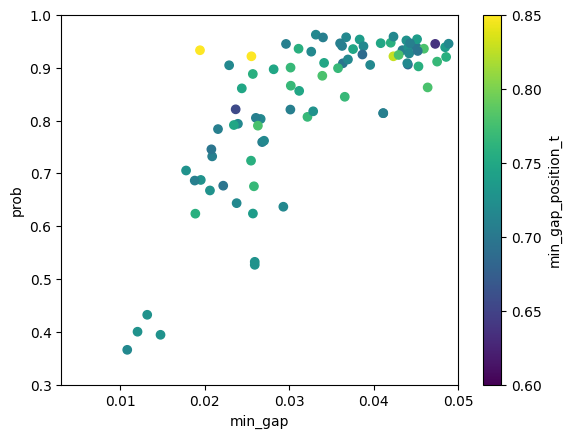

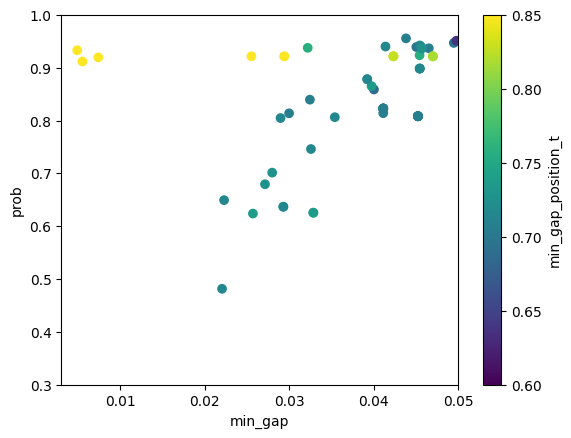

In [73]:
ps = [1, 2, 5, 8, 9]
for i in range(len(ps)):
    fig = plot_scatter(f"benchmarkResults/energies/qa_energies_results_maxclique_er_n10_p0{ps[i]}.json", 
                    color="tab:red", 
                    label="ER", 
                    attr1="min_gap", 
                    attr2="prob", 
                    attr3="min_gap_position_t", 
                    alpha=1, 
                    cmap_range=(0.6, 0.85), 
                    xlim=(0.003, 0.05), 
                    ylim=(0.3, 1)

                    # attr1="min_gap_position_t", 
                    # attr2="min_gap", 
                    # attr3="prob", 
                    # alpha=0.6, 
                    # cmap_range=(0.2, 1), 
                    # xlim=(0.5, 0.95), 
                    # ylim=(0.001, 0.11)
                )

qa maxclique, hard classical er instances

{'graph': ['0 3 6 7 1 2 4', '1 5 6 7 9 2 3 4', '2 3 4 5 9', '3 4 8 9', '4 5 6 7 8', '5 6 7 9 8', '6 8 7', '7 8', '8', '9'], 'k': 5}
{'1', '6', '7', '5', '4'}
7.590001041535288e-05
0.00021689999266527593


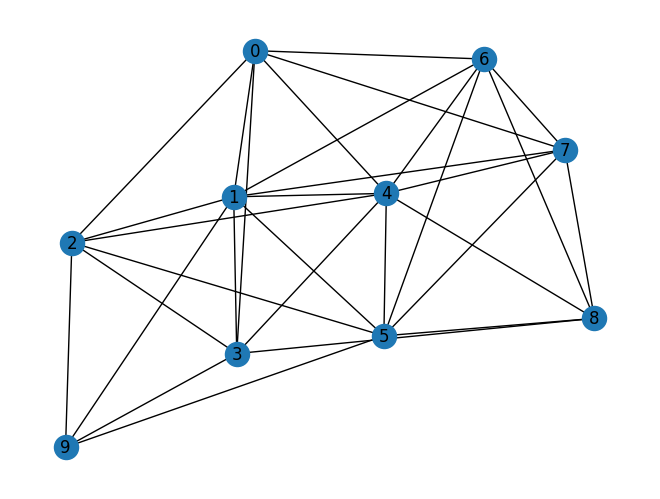

In [87]:
# one hard instance visualization
from src.max_clique_github.max_clique.main import get_max_clique
import timeit
with open("benchmark_data/er_hard_classical/max_clique/er_10_05") as f:
    data = json.load(f)

hard_instance = data[0]
graph = nx.parse_adjlist(hard_instance["graph"])
print(hard_instance)

t1 = timeit.default_timer()
print(get_max_clique(graph))
t2 = timeit.default_timer()
print(t2 - t1)

er_graph = nx.erdos_renyi_graph(10, 0.5)
t1 = timeit.default_timer()
get_max_clique(er_graph)
t2 = timeit.default_timer()
print(t2 - t1)
nx.draw(graph, with_labels=True)
plt.show()


#### Comparing instances from G(10, 0.5) and isolated hard ones according to a classical algorithm

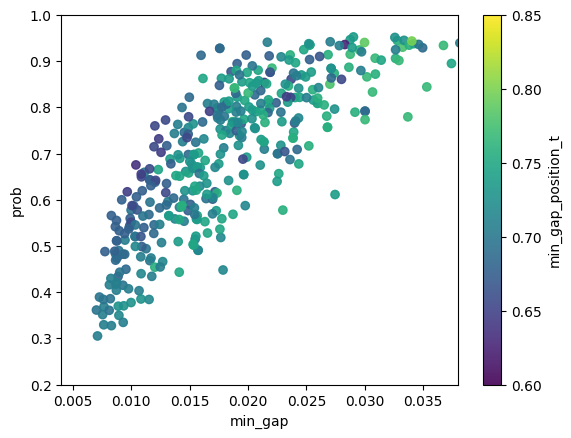

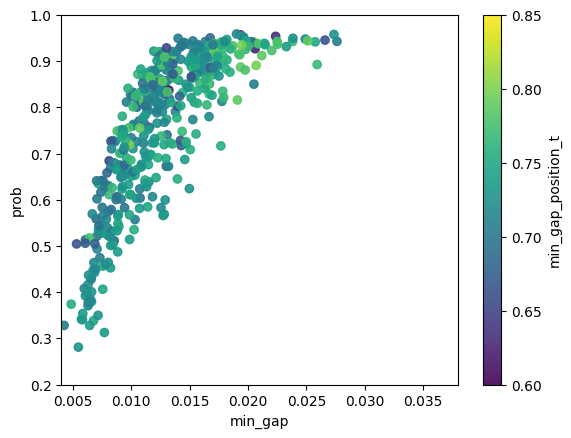

In [72]:
fig = plot_scatter("benchmarkResults/energies/qa_energies_results_maxclique_clas_hard_n10_p05_4.json", 
                   attr1="min_gap", 
                   attr2="prob", 
                   attr3="min_gap_position_t", 
                   color="tab:red", label="ER", column=0, alpha=0.9, cmap_range=(0.6, 0.85), xlim=(0.004, 0.038), ylim=(0.2, 1))
fig = plot_scatter("benchmarkResults/energies/qa_energies_results_maxclique_er_n10_p05_3.json", 
                   attr1="min_gap", 
                   attr2="prob", 
                   attr3="min_gap_position_t", 
                   color="tab:red", label="ER", column=0, alpha=0.9, cmap_range=(0.6, 0.85), xlim=(0.004, 0.038), ylim=(0.2, 1))

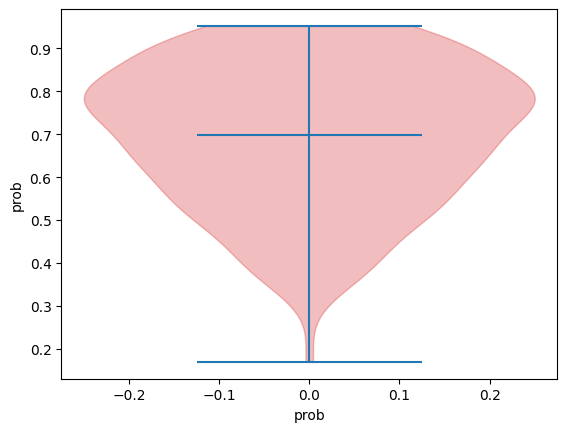

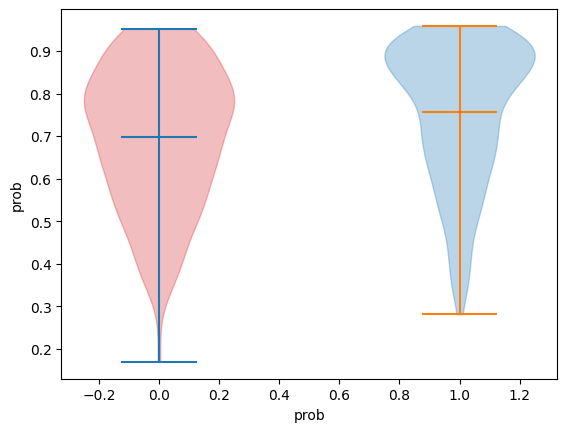

In [69]:
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_clas_hard_n10_p05_4.json", plot="bar violin", attribute="prob", color="tab:red", label="ER", column=0, alpha=0.01)
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_er_n10_p05_3.json", plot="bar violin", attribute="prob", color="tab:blue", label="ER", column=1, alpha=0.01, fig=fig)

Average probability: 0.7171272360599573
Average min gap size: 0.013221874296630366


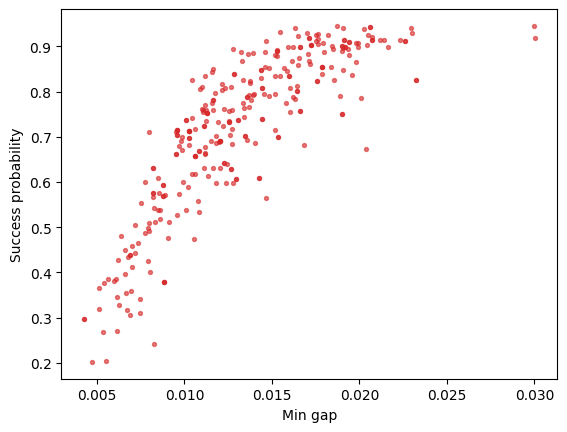

Average probability: 0.7557194148601074
Average min gap size: 0.01303054666066424


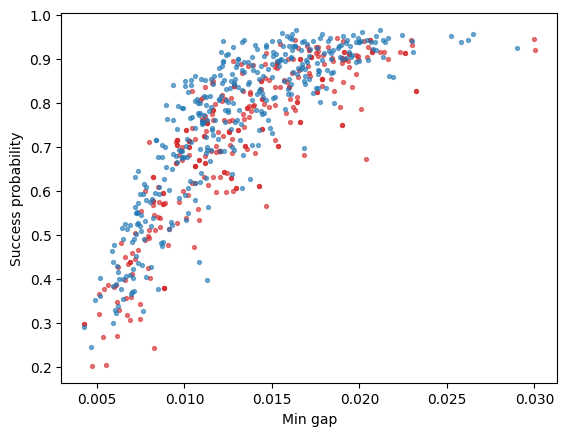

In [179]:
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_clas_hard_n10_p05_2.json", plot="gap vs prob", color="tab:red", label="ER", xscale="linear")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_er_n10_p05_2.json", plot="gap vs prob", color="tab:blue", label="ER", xscale="linear", fig=fig)

qa maxclique, kcores

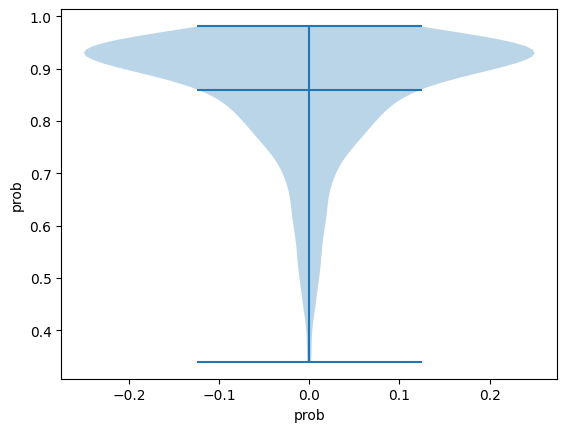

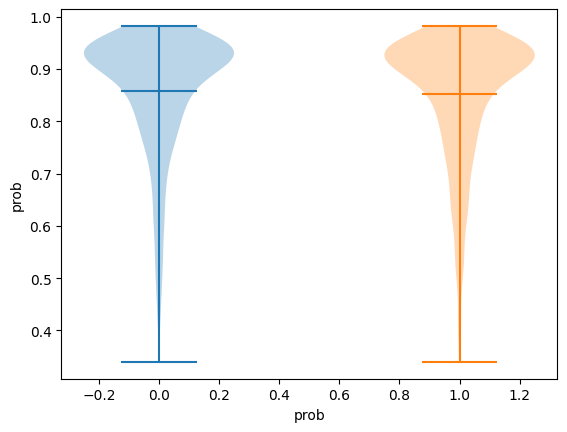

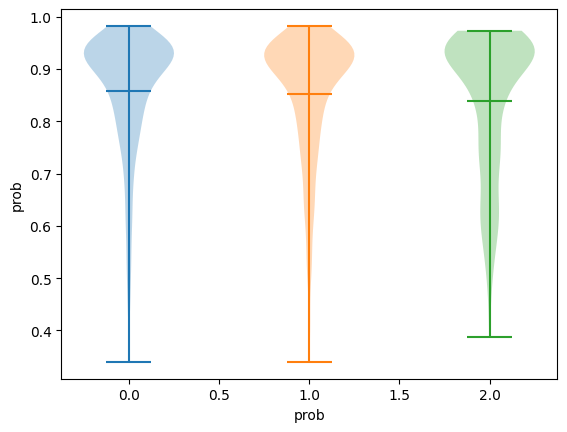

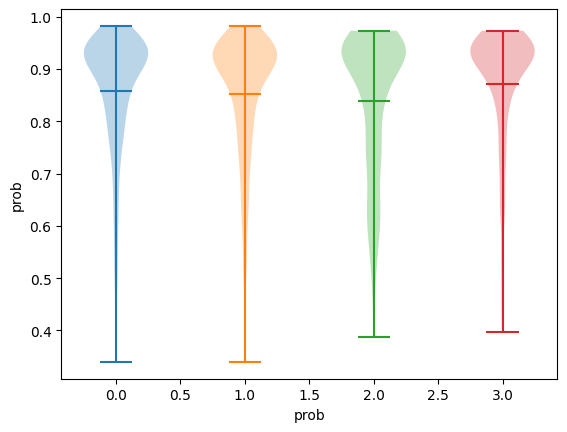

In [122]:
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore1.json", plot="bar violin", attribute="prob", color="tab:red", label="ER", column=0, alpha=0.01)
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore2.json", plot="bar violin", attribute="prob", fig=fig, color="tab:green", label="2-core", column=1, alpha=0.01)
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore3.json", plot="bar violin", attribute="prob", fig=fig, color="tab:blue", label="3-core", column=2, alpha=0.01)
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore4.json", plot="bar violin", attribute="prob", fig=fig, color="tab:orange", label="4-core", column=3, alpha=0.01)

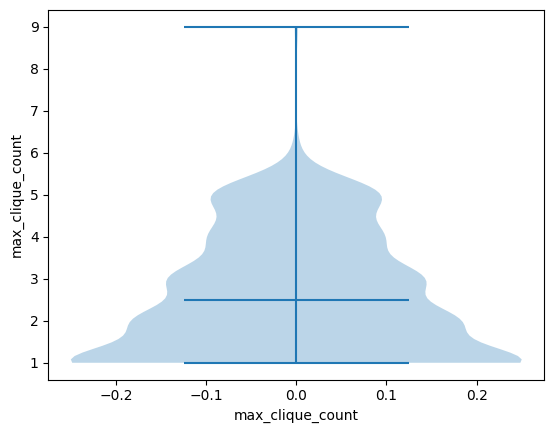

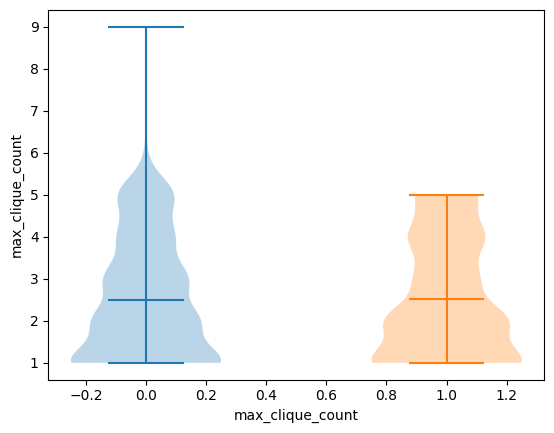

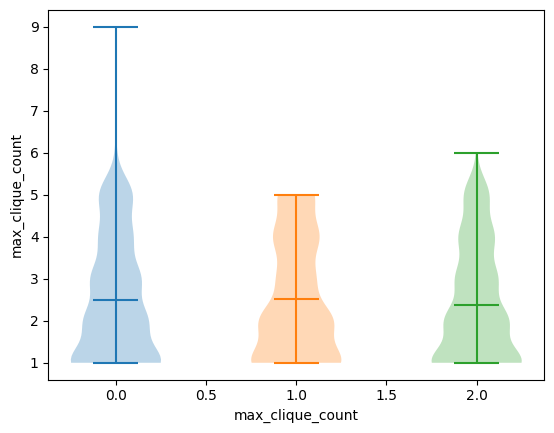

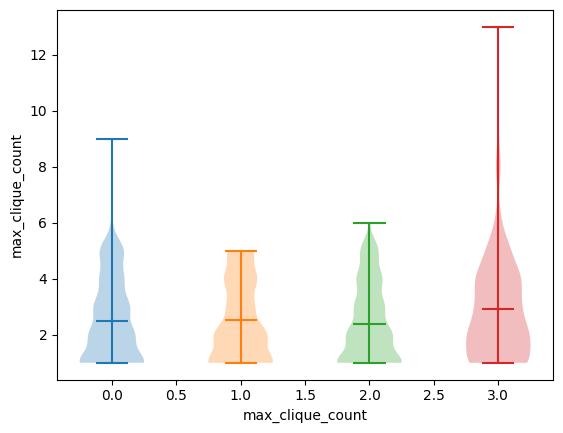

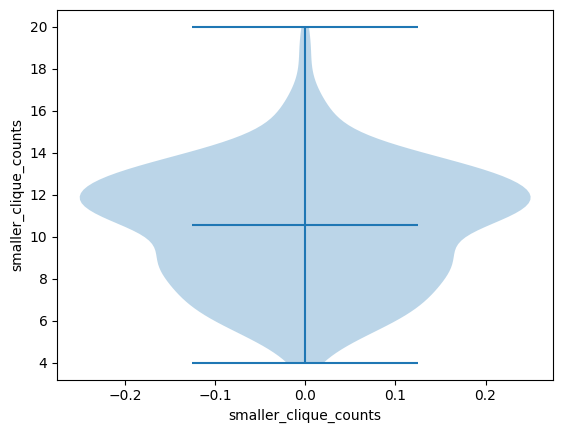

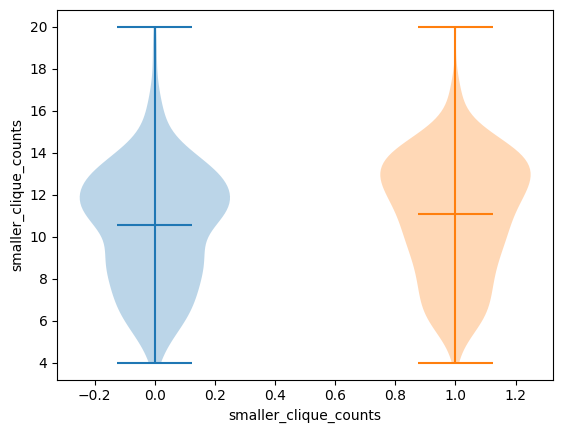

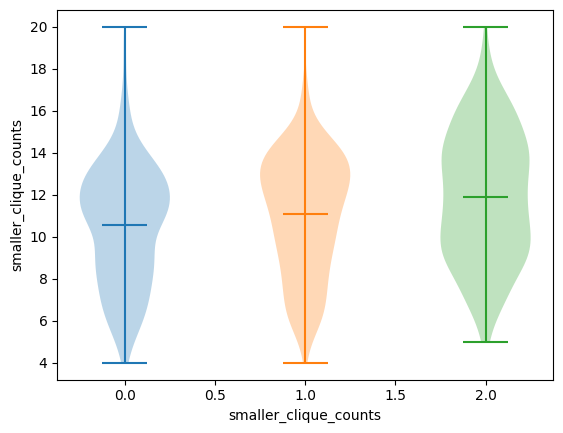

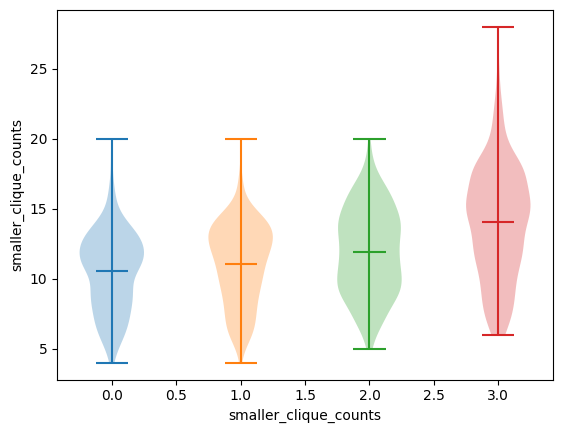

In [121]:
# visualize k-core graph properties
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore1.json", plot="bar violin", attribute="max_clique_count", color="tab:red", label="ER", bins=7, column=0, alpha=0.01)
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore2.json", plot="bar violin", attribute="max_clique_count", fig=fig, color="tab:green", label="2-core", bins=12, column=1, alpha=0.01)
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore3.json", plot="bar violin", attribute="max_clique_count", fig=fig, color="tab:blue", label="3-core", bins=12, column=2, alpha=0.01)
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore4.json", plot="bar violin", attribute="max_clique_count", fig=fig, color="tab:orange", label="4-core", bins=12, column=3, alpha=0.01)

fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore1.json", plot="bar violin", attribute="smaller_clique_counts", color="tab:red", label="ER", bins=7, column=0, alpha=0.01, attribute_mapping=lambda x: x[0])
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore2.json", plot="bar violin", attribute="smaller_clique_counts", fig=fig, color="tab:green", label="2-core", bins=12, column=1, alpha=0.01, attribute_mapping=lambda x: x[0])
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore3.json", plot="bar violin", attribute="smaller_clique_counts", fig=fig, color="tab:blue", label="3-core", bins=12, column=2, alpha=0.01, attribute_mapping=lambda x: x[0])
fig = plot_graph_info("benchmarkResults/energies/qa_energies_results_maxclique_kcore4.json", plot="bar violin", attribute="smaller_clique_counts", fig=fig, color="tab:orange", label="4-core", bins=12, column=3, alpha=0.01, attribute_mapping=lambda x: x[0])

qa kclique, different B

Average probability: 0.7568609900406368
Average min gap size: 0.01335765429538369


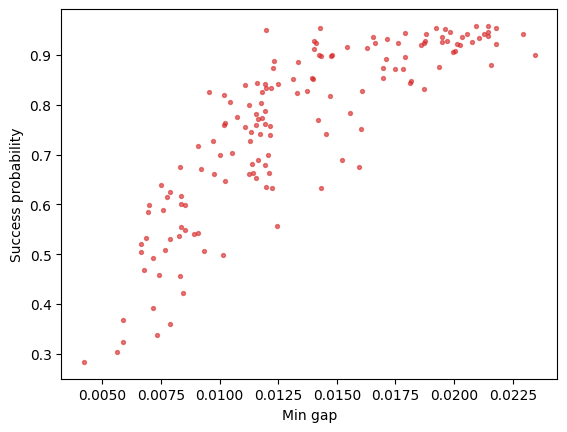

Average probability: 0.7670739706050036
Average min gap size: 0.013604883784889043


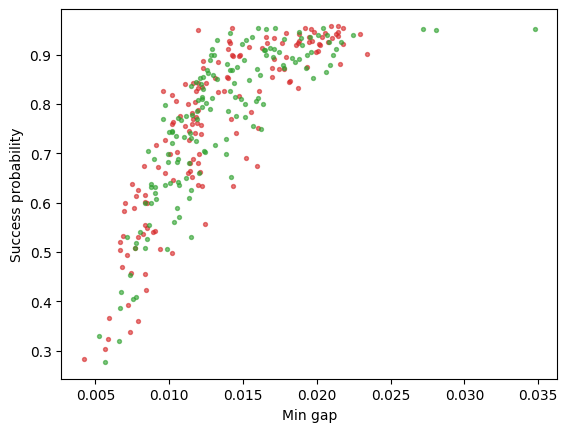

Average probability: 0.7940617544626924
Average min gap size: 0.01588196030637001


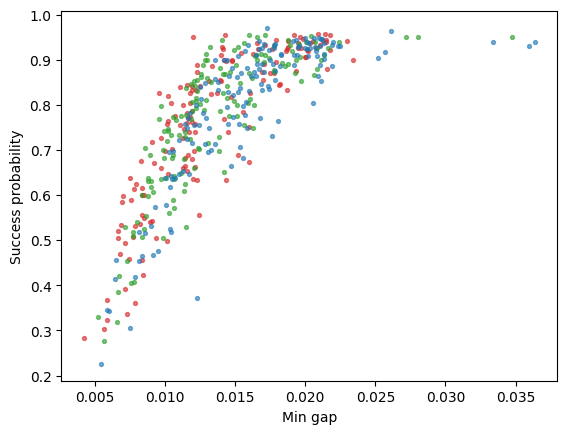

Average probability: 0.7622039354013668
Average min gap size: 0.017364288508814704


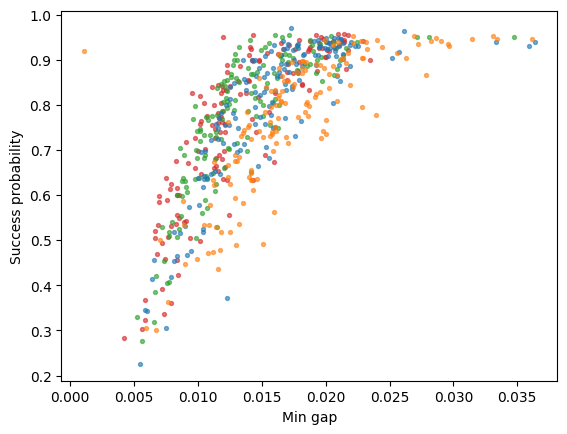

In [113]:
# visualize different k-cores
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_kcore1_n10.json", plot="gap vs prob", color="tab:red", label="ER", xscale="linear")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_kcore2_n10.json", plot="gap vs prob", fig=fig, color="tab:green", label="2-core", xscale="linear")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_kcore3_n10.json", plot="gap vs prob", fig=fig, color="tab:blue", label="3-core", xscale="linear")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_kcore4_n10.json", plot="gap vs prob", fig=fig, color="tab:orange", label="4-core", xscale="linear")

Average probability: 0.8519942544864999
Average min gap size: 0.02501668789912493


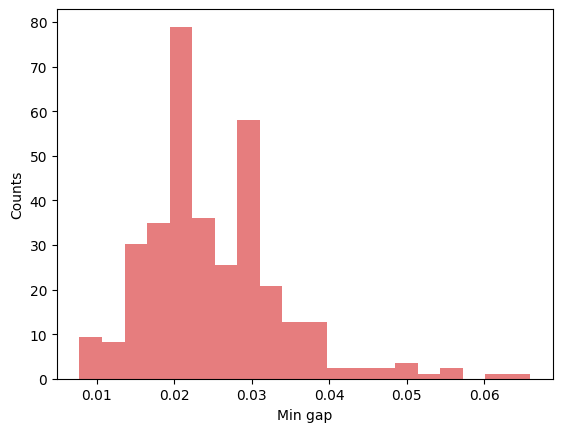

Average probability: 0.8589188427315163
Average min gap size: 0.027658030892392636


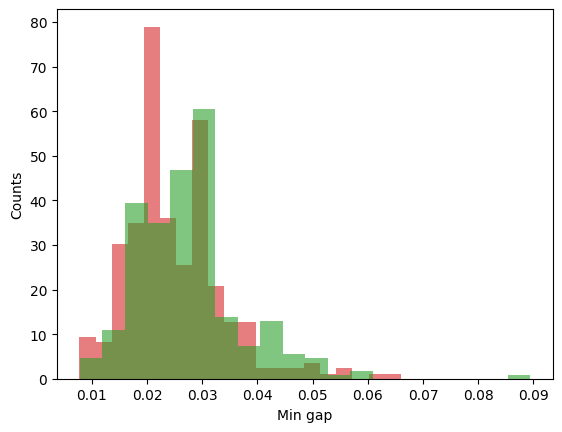

Average probability: 0.8434771713894837
Average min gap size: 0.03478086665032245


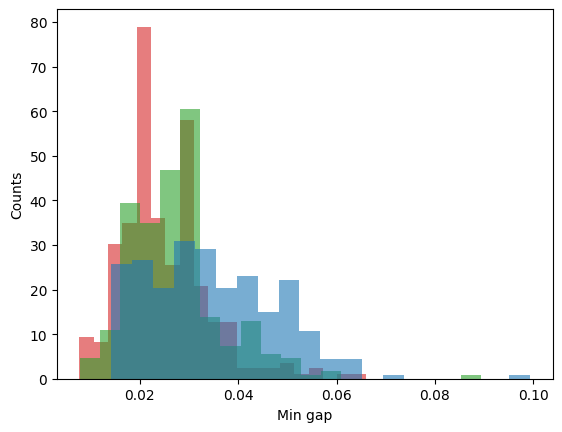

Average probability: 0.8633417550028202
Average min gap size: 0.049773017895629344


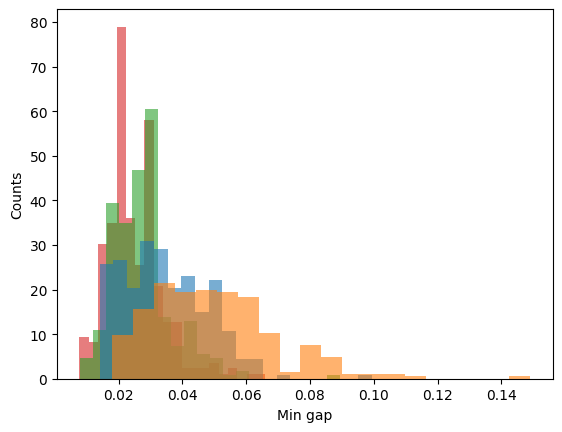

In [112]:
# visualize different k-cores
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_kcore1.json", plot="gap hist", color="tab:red", label="ER")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_kcore2.json", plot="gap hist", fig=fig, color="tab:green", label="2-core")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_kcore3.json", plot="gap hist", fig=fig, color="tab:blue", label="3-core")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_kcore4.json", plot="gap hist", fig=fig, color="tab:orange", label="4-core")

{'samples': [{'min_gap': 0.0069634039903414, 'prob': 0.4984983526732672}, {'min_gap': 0.013198467795132424, 'prob': 0.8346186506663879}, {'min_gap': 0.012769675324513969, 'prob': 0.7851157254353791}, {'min_gap': 0.012224763107756168, 'prob': 0.684789644025769}, {'min_gap': 0.009696476150004213, 'prob': 0.6378980852178555}, {'min_gap': 0.011466074174542214, 'prob': 0.7468774239885821}, {'min_gap': 0.015457057557971346, 'prob': 0.9051033348640276}, {'min_gap': 0.010671604152097827, 'prob': 0.6830893350440862}, {'min_gap': 0.007886864318702596, 'prob': 0.5499186404388968}, {'min_gap': 0.006627255360022701, 'prob': 0.40666955127884263}, {'min_gap': 0.012826071092915538, 'prob': 0.7565427552717494}, {'min_gap': 0.01248327400766732, 'prob': 0.78121025318119}, {'min_gap': 0.0073939541169807345, 'prob': 0.5158862978889066}, {'min_gap': 0.012182789879119112, 'prob': 0.7956629220575544}, {'min_gap': 0.010737734552998736, 'prob': 0.7826162413384907}, {'min_gap': 0.011134480905402266, 'prob': 0.73

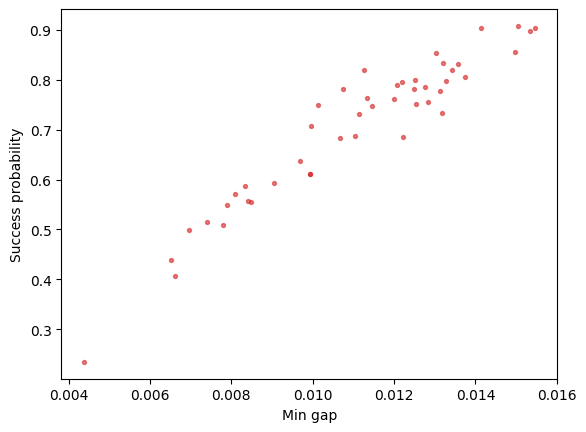

{'samples': [{'min_gap': 0.007286824516959591, 'prob': 0.8349903099147392}, {'min_gap': 0.013224042202180408, 'prob': 0.9577789018241656}, {'min_gap': 0.013559095610892935, 'prob': 0.9692270464864131}, {'min_gap': 0.014557483246337856, 'prob': 0.9721901681353055}, {'min_gap': 0.010804118866000295, 'prob': 0.9316432200261502}, {'min_gap': 0.0036906511846724246, 'prob': 0.4145657969932149}, {'min_gap': 0.012375857351139762, 'prob': 0.9550447632833554}, {'min_gap': 0.00989108588954934, 'prob': 0.8524283708961253}, {'min_gap': 0.013695204114520463, 'prob': 0.9644066060372911}, {'min_gap': 0.012053096138767204, 'prob': 0.9638741534868943}, {'min_gap': 0.00944750796047626, 'prob': 0.8809828886519306}, {'min_gap': 0.01277233617765294, 'prob': 0.9652716971268347}, {'min_gap': 0.01244969661840119, 'prob': 0.9646092967641977}, {'min_gap': 0.012880122379348258, 'prob': 0.9656352313782837}, {'min_gap': 0.013499844327940304, 'prob': 0.9721452211265419}, {'min_gap': 0.014493971066587681, 'prob': 0.9

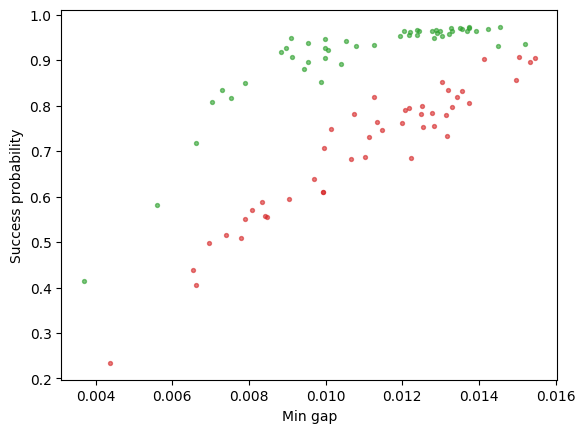

{'samples': [{'min_gap': 0.01083376774258263, 'prob': 0.9596987730981573}, {'min_gap': 0.010099394831320382, 'prob': 0.9491525990782047}, {'min_gap': 0.0050334560217034675, 'prob': 0.8907896122924971}, {'min_gap': 0.006042504877983766, 'prob': 0.8885053115815892}, {'min_gap': 0.008039328089150333, 'prob': 0.9634385498082814}, {'min_gap': 0.008399425140679987, 'prob': 0.949938585857133}, {'min_gap': 0.007068914740369115, 'prob': 0.9646972031115457}, {'min_gap': 0.009966023802818816, 'prob': 0.9730780555498904}, {'min_gap': 0.0105612106531989, 'prob': 0.9786611293585255}, {'min_gap': 0.01033969788058934, 'prob': 0.9738793523200426}, {'min_gap': 0.00806779866316234, 'prob': 0.9431997728826657}, {'min_gap': 0.009443081503867069, 'prob': 0.9723650121628011}, {'min_gap': 0.006098991024512668, 'prob': 0.8946392245900376}, {'min_gap': 0.008218386749769926, 'prob': 0.9542983830306301}, {'min_gap': 0.007023836565487667, 'prob': 0.9517067247176987}, {'min_gap': 0.008324748829107187, 'prob': 0.945

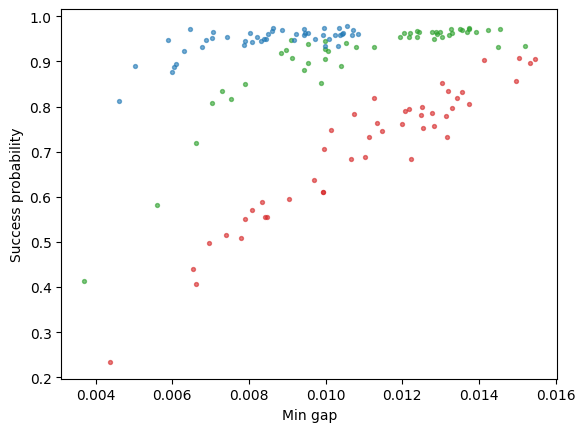

{'samples': [{'min_gap': 0.005293913806186342, 'prob': 0.9254526606757664}, {'min_gap': 0.0049881553238019655, 'prob': 0.935980552650886}, {'min_gap': 0.004412678315514144, 'prob': 0.9247737029341137}, {'min_gap': 0.005533180561623739, 'prob': 0.9440433038993303}, {'min_gap': 0.00541364719480602, 'prob': 0.9685416292012771}, {'min_gap': 0.006633762303569291, 'prob': 0.9701924643901604}, {'min_gap': 0.0060584067603320175, 'prob': 0.9642750716075905}, {'min_gap': 0.004944404005238087, 'prob': 0.9723883873490304}, {'min_gap': 0.00628983130171483, 'prob': 0.9333589893492031}, {'min_gap': 0.00457266595439091, 'prob': 0.9381894920892813}, {'min_gap': 0.004542275664026973, 'prob': 0.9186889242009564}, {'min_gap': 0.0063261344173003485, 'prob': 0.976370302199711}, {'min_gap': 0.005814233897505509, 'prob': 0.9554525571518979}, {'min_gap': 0.003634720634322573, 'prob': 0.8976602503072261}, {'min_gap': 0.004264665746878322, 'prob': 0.9283655248296158}, {'min_gap': 0.004517763124216695, 'prob': 0.

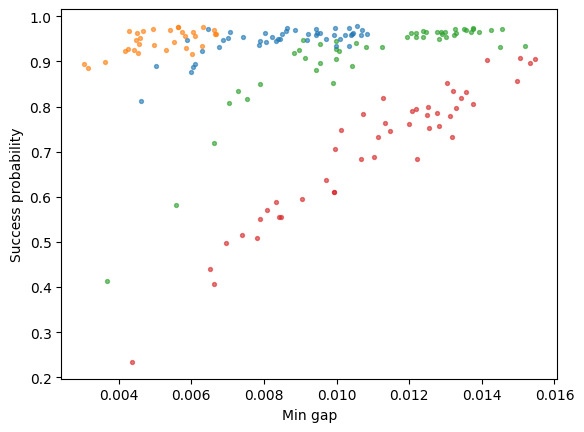

{'samples': [{'min_gap': 0.0021012666873539594, 'prob': 0.8965540317336278}, {'min_gap': 0.0029041935257535364, 'prob': 0.9151927090509835}, {'min_gap': 0.0032680444151500492, 'prob': 0.8668341135428784}, {'min_gap': 0.002691746338737317, 'prob': 0.9535562825641694}, {'min_gap': 0.003016648273597839, 'prob': 0.9052213157124192}, {'min_gap': 0.00334467184085714, 'prob': 0.9199174871132921}, {'min_gap': 0.002921940214232981, 'prob': 0.9189876273285238}, {'min_gap': 0.0032865905113285765, 'prob': 0.837731946808066}, {'min_gap': 0.002510712879197547, 'prob': 0.9171470110527689}, {'min_gap': 0.003455104554018593, 'prob': 0.8862521968492193}, {'min_gap': 0.0013277567771556964, 'prob': 0.6902959147007157}, {'min_gap': 0.002166810828229617, 'prob': 0.842604916788324}, {'min_gap': 0.003136601109226221, 'prob': 0.8937105346733888}, {'min_gap': 0.0026313496955531874, 'prob': 0.8949696075837815}, {'min_gap': 0.0018443715919042357, 'prob': 0.8396618923988829}, {'min_gap': 0.0033070854194524233, 'pr

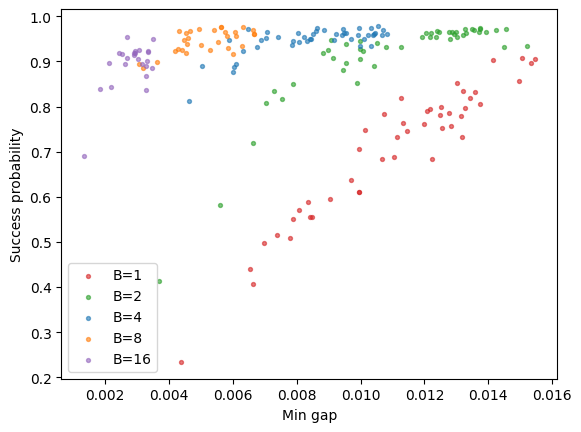

In [27]:
# visualize different B
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_kclique_B1.json", plot="gap vs prob", color="tab:red", label="B=1")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_kclique_B2.json", plot="gap vs prob", fig=fig, color="tab:green", label="B=2")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_kclique_B4.json", plot="gap vs prob", fig=fig, color="tab:blue", label="B=4")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_kclique_B8.json", plot="gap vs prob", fig=fig, color="tab:orange", label="B=8")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_kclique_B16.json", plot="gap vs prob", fig=fig, color="tab:purple", label="B=16", legend=True)

qa maxclique, different B

{'samples': [{'min_gap': 0.001282730761127615, 'prob': 0.5638762798967185}, {'min_gap': 0.00128583172848723, 'prob': 0.5084642607869512}, {'min_gap': 0.03455460266737276, 'prob': 0.7353111524190745}, {'min_gap': 0.0027913707166762336, 'prob': 0.5502982582140798}, {'min_gap': 0.0010860534965527746, 'prob': 0.42676397092351476}, {'min_gap': 0.002401088597211054, 'prob': 0.4837884439745896}, {'min_gap': 0.02090759280587734, 'prob': 0.4693619185735991}, {'min_gap': 0.0010300870684732955, 'prob': 0.471926223983467}, {'min_gap': 0.002048843697920244, 'prob': 0.3674994967424894}, {'min_gap': 0.0024155515705593655, 'prob': 0.3732304283908392}, {'min_gap': 0.02167391213599218, 'prob': 0.5185571961674844}, {'min_gap': 0.024287059784955656, 'prob': 0.5418924796746939}, {'min_gap': 0.021910491245016178, 'prob': 0.44462798321224734}, {'min_gap': 0.0010997674747607877, 'prob': 0.49240760465586875}, {'min_gap': 0.024908671366223684, 'prob': 0.5163004233253008}, {'min_gap': 0.001540891334942257, 'prob

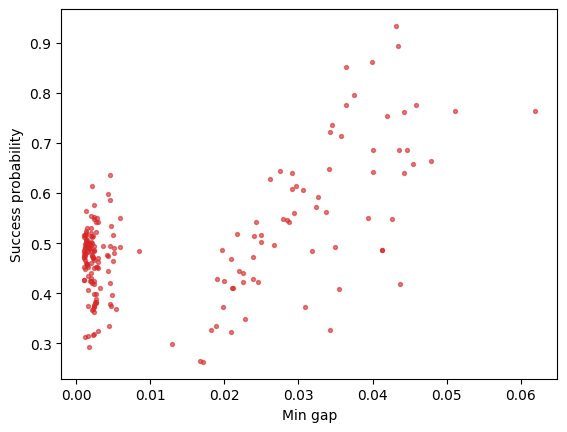

{'samples': [{'min_gap': 0.009506492148160225, 'prob': 0.5197587249928666}, {'min_gap': 0.021040224518512146, 'prob': 0.9416262935905078}, {'min_gap': 0.015350682284453632, 'prob': 0.8305589937256448}, {'min_gap': 0.025878007303405726, 'prob': 0.9521005039008322}, {'min_gap': 0.026248959119617235, 'prob': 0.9488764424590556}, {'min_gap': 0.007932361654413522, 'prob': 0.41621719531448087}, {'min_gap': 0.03136053759788347, 'prob': 0.9430745207986072}, {'min_gap': 0.036449077618695785, 'prob': 0.9551002553506817}, {'min_gap': 0.021909310061091952, 'prob': 0.9708997230417655}, {'min_gap': 0.02227555066015506, 'prob': 0.9090919292934496}, {'min_gap': 0.019573184108615388, 'prob': 0.7733447265496222}, {'min_gap': 0.022543965383414855, 'prob': 0.9520181507336773}, {'min_gap': 0.01251572682217611, 'prob': 0.7432686031064064}, {'min_gap': 0.009553345143686304, 'prob': 0.5434803975659867}, {'min_gap': 0.007850672645276058, 'prob': 0.39934338154676674}, {'min_gap': 0.03149093387268684, 'prob': 0.

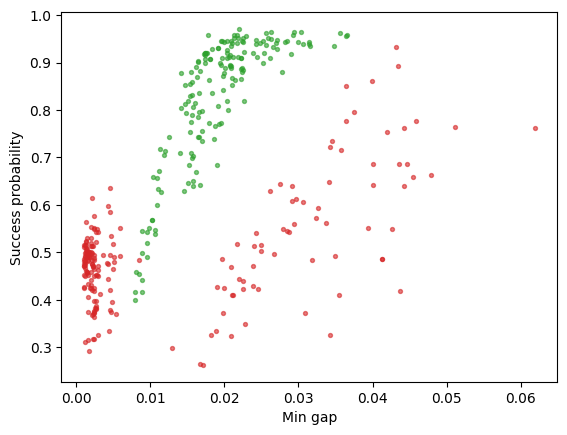

{'samples': [{'min_gap': 0.010079264659938116, 'prob': 0.8753783829088448}, {'min_gap': 0.011100037109036266, 'prob': 0.9704130915492358}, {'min_gap': 0.010073662986183674, 'prob': 0.9214839547634076}, {'min_gap': 0.008182108623842756, 'prob': 0.9237840772240211}, {'min_gap': 0.013666029017557153, 'prob': 0.9711522526571881}, {'min_gap': 0.006374476125947399, 'prob': 0.8845074825943234}, {'min_gap': 0.008230441257125055, 'prob': 0.9427111941910509}, {'min_gap': 0.005911906223949492, 'prob': 0.7289414499514163}, {'min_gap': 0.012513690994295841, 'prob': 0.974722905890247}, {'min_gap': 0.010110096668359554, 'prob': 0.9165568896943128}, {'min_gap': 0.012655112897709826, 'prob': 0.960746412412268}, {'min_gap': 0.01148994424129235, 'prob': 0.9631957807687694}, {'min_gap': 0.01203948925781927, 'prob': 0.9739060368109349}, {'min_gap': 0.008725153997525645, 'prob': 0.9552924292319771}, {'min_gap': 0.005118036739807728, 'prob': 0.6310457452078329}, {'min_gap': 0.006027934656559812, 'prob': 0.84

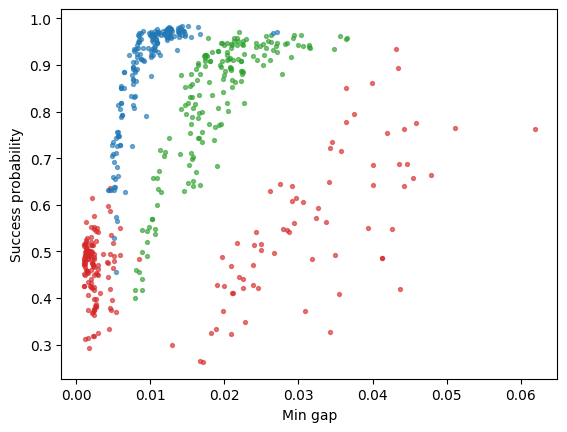

{'samples': [{'min_gap': 0.005252161456579439, 'prob': 0.9625145704080741}, {'min_gap': 0.006830582328337817, 'prob': 0.9661303641905208}, {'min_gap': 0.0026491341603890987, 'prob': 0.7159806873233093}, {'min_gap': 0.005430892871149565, 'prob': 0.9216562854130746}, {'min_gap': 0.005358000914474963, 'prob': 0.9720217475131998}, {'min_gap': 0.0054802815941949155, 'prob': 0.95898609908852}, {'min_gap': 0.005435628562533596, 'prob': 0.9528132549995492}, {'min_gap': 0.003921198779816828, 'prob': 0.8912153746429665}, {'min_gap': 0.007657352482046884, 'prob': 0.947302823028499}, {'min_gap': 0.00550721368547138, 'prob': 0.9537866688554293}, {'min_gap': 0.006055763829933638, 'prob': 0.9747726204306707}, {'min_gap': 0.004202289251450542, 'prob': 0.9251882027919266}, {'min_gap': 0.005353753229154169, 'prob': 0.9495280174692552}, {'min_gap': 0.006179554015875326, 'prob': 0.9652484699877005}, {'min_gap': 0.00687028274166563, 'prob': 0.9657641768172587}, {'min_gap': 0.0045249623996543795, 'prob': 0.

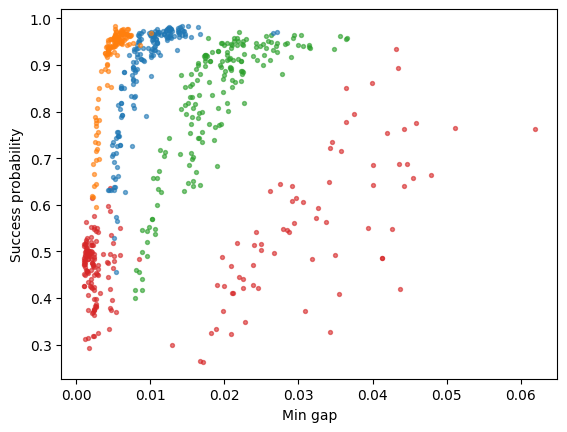

{'samples': [{'min_gap': 0.002091537864152832, 'prob': 0.8944122801910829}, {'min_gap': 0.0032125682237729523, 'prob': 0.9140421372240466}, {'min_gap': 0.0019055420341392206, 'prob': 0.8359306358147776}, {'min_gap': 0.0031935922612245544, 'prob': 0.9297521660656893}, {'min_gap': 0.002073311569335521, 'prob': 0.8788465079506547}, {'min_gap': 0.0029571886513935774, 'prob': 0.9133527965640549}, {'min_gap': 0.0027758751314943646, 'prob': 0.9188567487500505}, {'min_gap': 0.003371502302129326, 'prob': 0.9197058633405206}, {'min_gap': 0.0014156856194468938, 'prob': 0.7553986565849892}, {'min_gap': 0.0011775948094260233, 'prob': 0.6739308848986959}, {'min_gap': 0.0016831234856856288, 'prob': 0.8406085325704352}, {'min_gap': 0.001425902012092823, 'prob': 0.813156362443723}, {'min_gap': 0.003241916215342448, 'prob': 0.9341692733410691}, {'min_gap': 0.002152333622531309, 'prob': 0.9249407268313372}, {'min_gap': 0.002691905069984832, 'prob': 0.8848080111460286}, {'min_gap': 0.0033816012866115432, 

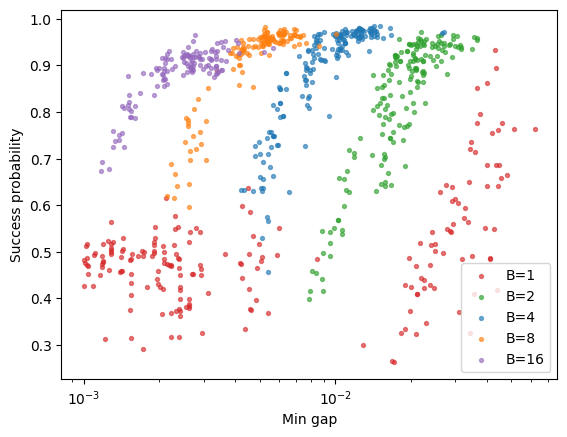

In [33]:
# visualize different B
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_B1.json", plot="gap vs prob", color="tab:red", label="B=1")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_B2.json", plot="gap vs prob", fig=fig, color="tab:green", label="B=2")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_B4.json", plot="gap vs prob", fig=fig, color="tab:blue", label="B=4")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_B8.json", plot="gap vs prob", fig=fig, color="tab:orange", label="B=8")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_B16.json", plot="gap vs prob", fig=fig, xscale="log", color="tab:purple", label="B=16", legend=True)

{'samples': [{'min_gap': 0.011002409324720415, 'prob': 0.6148580975422449}, {'min_gap': 0.0144186290090851, 'prob': 0.8105254204712917}, {'min_gap': 0.01953234969117794, 'prob': 0.8812334079063026}, {'min_gap': 0.01722704517433725, 'prob': 0.8769235609882731}, {'min_gap': 0.014750995215237048, 'prob': 0.9175655912818267}, {'min_gap': 0.015068060628725542, 'prob': 0.8522029265351045}, {'min_gap': 0.008331968317385783, 'prob': 0.7346867458100759}, {'min_gap': 0.008503091001507809, 'prob': 0.7234633468669639}, {'min_gap': 0.012839229917742861, 'prob': 0.9144103608023324}, {'min_gap': 0.009757873430939389, 'prob': 0.765865561763086}, {'min_gap': 0.014705808313932017, 'prob': 0.8480838334878804}, {'min_gap': 0.020047156872034316, 'prob': 0.956255961181216}, {'min_gap': 0.01587307361651321, 'prob': 0.9607040993493571}, {'min_gap': 0.02704196436191707, 'prob': 0.9742159813073734}, {'min_gap': 0.018523821358607934, 'prob': 0.8994307610169898}, {'min_gap': 0.011096984545353782, 'prob': 0.804338

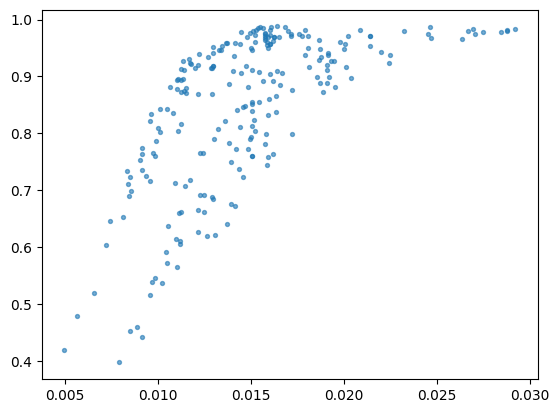

{'samples': [{'min_gap': 0.01251821742967842, 'prob': 0.8057842799884898}, {'min_gap': 0.013073663741343628, 'prob': 0.6990215254643467}, {'min_gap': 0.013183135169280144, 'prob': 0.7424822861159751}, {'min_gap': 0.019074785172535462, 'prob': 0.9408273326323059}, {'min_gap': 0.005292691988669033, 'prob': 0.4013129750020995}, {'min_gap': 0.015229198668843442, 'prob': 0.8869101630349892}, {'min_gap': 0.011449972790117065, 'prob': 0.7498611404613144}, {'min_gap': 0.015010001195821755, 'prob': 0.8772649089827512}, {'min_gap': 0.01664192225182808, 'prob': 0.9108524154747819}, {'min_gap': 0.012922025435942956, 'prob': 0.6970976519201246}, {'min_gap': 0.013366203788364669, 'prob': 0.90287778595509}, {'min_gap': 0.01914565287092847, 'prob': 0.9362561113780605}, {'min_gap': 0.017980673266224045, 'prob': 0.8691302201519175}, {'min_gap': 0.02853355818003711, 'prob': 0.9511972258584656}, {'min_gap': 0.014738556049287239, 'prob': 0.8290989476270493}, {'min_gap': 0.030329776933886325, 'prob': 0.9428

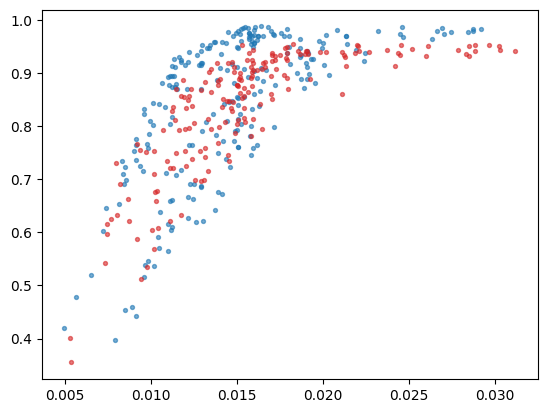

In [5]:
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_kclique_boquadratic.json", plot="gap vs prob", color="tab:blue")
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_kclique_linear.json", plot="gap vs prob", fig=fig, color="tab:red")

{'samples': [{'min_gap': 0.02811691730287058, 'prob': 0.7265393374471156}, {'min_gap': 0.0017185042050166244, 'prob': 0.5049502210226466}, {'min_gap': 0.0010761792116373153, 'prob': 0.6147751153397926}, {'min_gap': 0.001448760629147755, 'prob': 0.5464549826620322}, {'min_gap': 0.02808498178066038, 'prob': 0.7729128657928607}, {'min_gap': 0.0011565897814091175, 'prob': 0.5875235445062031}, {'min_gap': 0.03215228648570137, 'prob': 0.7948213330465392}, {'min_gap': 0.0016220109310327024, 'prob': 0.6217023683309058}, {'min_gap': 0.0015819918965547242, 'prob': 0.6950573642375828}, {'min_gap': 0.0014423773810322421, 'prob': 0.504164466300075}, {'min_gap': 0.0018925870457202065, 'prob': 0.5687831441997508}, {'min_gap': 0.018364501719587145, 'prob': 0.5398354673668109}, {'min_gap': 0.0016100622805219067, 'prob': 0.591482529849624}, {'min_gap': 0.0013135286188687145, 'prob': 0.5818481593209954}, {'min_gap': 0.03520684636276744, 'prob': 0.7366278430787956}, {'min_gap': 0.0156793062012094, 'prob':

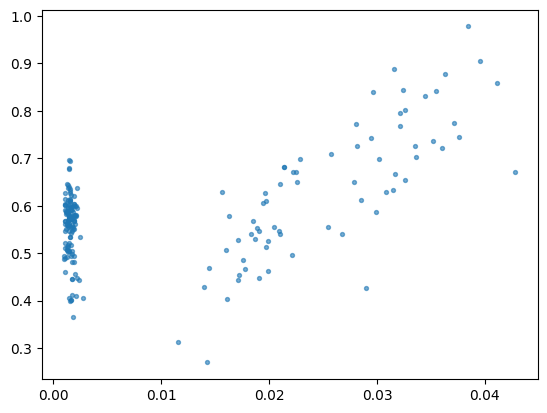

{'samples': [{'min_gap': 0.01251821742967842, 'prob': 0.8057842799884898}, {'min_gap': 0.013073663741343628, 'prob': 0.6990215254643467}, {'min_gap': 0.013183135169280144, 'prob': 0.7424822861159751}, {'min_gap': 0.019074785172535462, 'prob': 0.9408273326323059}, {'min_gap': 0.005292691988669033, 'prob': 0.4013129750020995}, {'min_gap': 0.015229198668843442, 'prob': 0.8869101630349892}, {'min_gap': 0.011449972790117065, 'prob': 0.7498611404613144}, {'min_gap': 0.015010001195821755, 'prob': 0.8772649089827512}, {'min_gap': 0.01664192225182808, 'prob': 0.9108524154747819}, {'min_gap': 0.012922025435942956, 'prob': 0.6970976519201246}, {'min_gap': 0.013366203788364669, 'prob': 0.90287778595509}, {'min_gap': 0.01914565287092847, 'prob': 0.9362561113780605}, {'min_gap': 0.017980673266224045, 'prob': 0.8691302201519175}, {'min_gap': 0.02853355818003711, 'prob': 0.9511972258584656}, {'min_gap': 0.014738556049287239, 'prob': 0.8290989476270493}, {'min_gap': 0.030329776933886325, 'prob': 0.9428

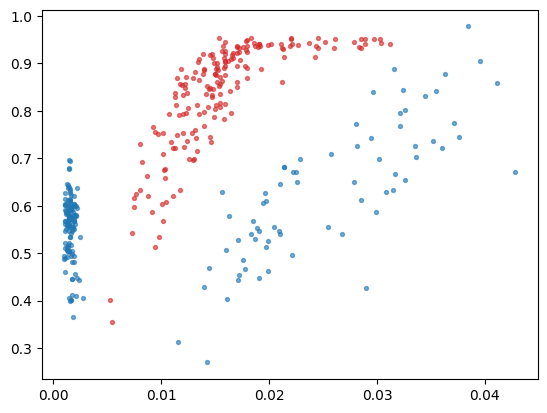

In [109]:
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_maxclique_linear.json", plot="gap vs prob", color="tab:blue")
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_kclique_linear.json", plot="gap vs prob", fig=fig, color="tab:red")

{'samples': [{'min_gap': 0.02811691730287058, 'prob': 0.7265393374471156}, {'min_gap': 0.0017185042050166244, 'prob': 0.5049502210226466}, {'min_gap': 0.0010761792116373153, 'prob': 0.6147751153397926}, {'min_gap': 0.001448760629147755, 'prob': 0.5464549826620322}, {'min_gap': 0.02808498178066038, 'prob': 0.7729128657928607}, {'min_gap': 0.0011565897814091175, 'prob': 0.5875235445062031}, {'min_gap': 0.03215228648570137, 'prob': 0.7948213330465392}, {'min_gap': 0.0016220109310327024, 'prob': 0.6217023683309058}, {'min_gap': 0.0015819918965547242, 'prob': 0.6950573642375828}, {'min_gap': 0.0014423773810322421, 'prob': 0.504164466300075}, {'min_gap': 0.0018925870457202065, 'prob': 0.5687831441997508}, {'min_gap': 0.018364501719587145, 'prob': 0.5398354673668109}, {'min_gap': 0.0016100622805219067, 'prob': 0.591482529849624}, {'min_gap': 0.0013135286188687145, 'prob': 0.5818481593209954}, {'min_gap': 0.03520684636276744, 'prob': 0.7366278430787956}, {'min_gap': 0.0156793062012094, 'prob':

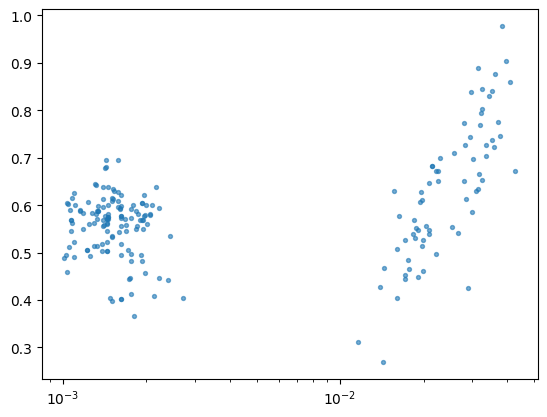

{'samples': [{'min_gap': 0.001774020251035624, 'prob': 0.6862169233129904}, {'min_gap': 0.041847953829306284, 'prob': 0.8201185024555994}, {'min_gap': 0.0019601752054769217, 'prob': 0.6770363883729266}, {'min_gap': 0.03515269682963493, 'prob': 0.8231357444202761}, {'min_gap': 0.031058198005061793, 'prob': 0.8937327237891866}, {'min_gap': 0.02534677655545292, 'prob': 0.8301219549994014}, {'min_gap': 0.0015232214553153878, 'prob': 0.6577349613037056}, {'min_gap': 0.0015055898989316252, 'prob': 0.5034713264019101}, {'min_gap': 0.001784074120026985, 'prob': 0.6225357566192421}, {'min_gap': 0.03851279604271465, 'prob': 0.8673100732609669}, {'min_gap': 0.0014627861575414736, 'prob': 0.7379935176764938}, {'min_gap': 0.0016406821771231678, 'prob': 0.6006307208357275}, {'min_gap': 0.05206882357395176, 'prob': 0.7739638948461084}, {'min_gap': 0.0014183968093533228, 'prob': 0.7588124915273898}, {'min_gap': 0.0015253326024461111, 'prob': 0.6570714619088001}, {'min_gap': 0.0015388899002194423, 'pro

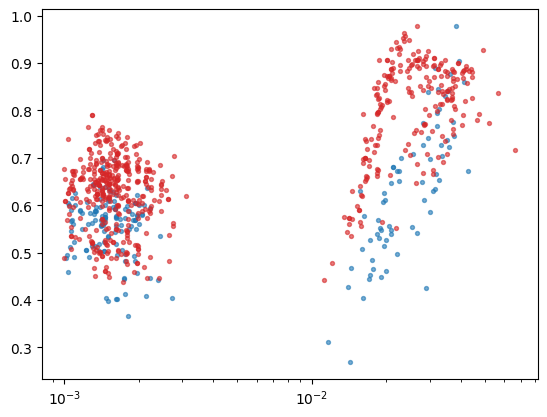

{'samples': [{'min_gap': 0.00829907631511878, 'prob': 0.5705197384756959}, {'min_gap': 0.005310196339337311, 'prob': 0.6968415708827376}, {'min_gap': 0.028828676590668817, 'prob': 0.9005047709453508}, {'min_gap': 0.0011303973766970676, 'prob': 0.5679647091105908}, {'min_gap': 0.0010123802083155664, 'prob': 0.60365928430627}, {'min_gap': 0.0010254285245581418, 'prob': 0.4188587961473421}, {'min_gap': 0.0076942375818634945, 'prob': 0.6208582909825773}, {'min_gap': 0.03656408456773602, 'prob': 0.941203464436331}, {'min_gap': 0.033122539509804455, 'prob': 0.7642650854493765}, {'min_gap': 0.0010450313393023103, 'prob': 0.5780051990849722}, {'min_gap': 0.007684940605218654, 'prob': 0.6958871326517617}, {'min_gap': 0.007694239810548176, 'prob': 0.6151759290538485}, {'min_gap': 0.04214453161423043, 'prob': 0.9294933956920423}, {'min_gap': 0.008307728153518656, 'prob': 0.6113459830117602}, {'min_gap': 0.023294757320794668, 'prob': 0.8077793099371706}, {'min_gap': 0.0010444455268995012, 'prob': 

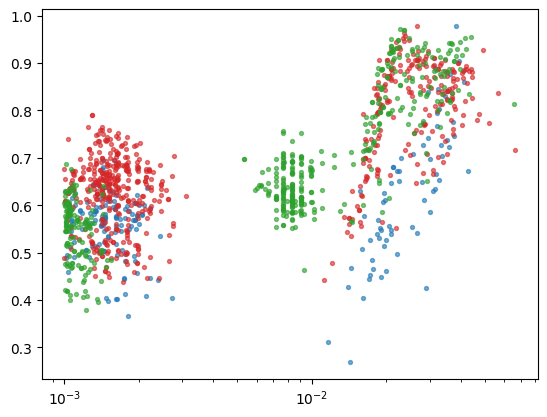

In [121]:
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_maxclique_linear.json", plot="gap vs prob", color="tab:blue", xscale="log")
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_maxclique_boquadratic.json", plot="gap vs prob", fig=fig, color="tab:red", xscale="log")
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_maxclique_lininterp.json", plot="gap vs prob", fig=fig, color="tab:green", xscale="log")

Plot maxclique at different B

{'samples': [{'min_gap': 0.0010269791065966594, 'prob': 0.5114474972124728}, {'min_gap': 0.0023615411092587357, 'prob': 0.5524378858136143}, {'min_gap': 0.0017250673303337294, 'prob': 0.49116225147931913}, {'min_gap': 0.00240860235128576, 'prob': 0.36317329712661106}, {'min_gap': 0.022521123556532546, 'prob': 0.4224602064553424}, {'min_gap': 0.04420937051513896, 'prob': 0.7622573728901272}, {'min_gap': 0.0010055678208016616, 'prob': 0.4259067034082083}, {'min_gap': 0.002406917842543349, 'prob': 0.39838386191408903}, {'min_gap': 0.023826326925832864, 'prob': 0.4289175118115915}, {'min_gap': 0.0012856467217954304, 'prob': 0.5040351135566725}, {'min_gap': 0.029729733549012705, 'prob': 0.6135369399051692}, {'min_gap': 0.01887000361718652, 'prob': 0.3341257806987417}, {'min_gap': 0.0013049016674817338, 'prob': 0.5210148080296643}, {'min_gap': 0.001539505098445193, 'prob': 0.4532058087976881}, {'min_gap': 0.0023178086180286606, 'prob': 0.5764569625534083}, {'min_gap': 0.002232492758071386, '

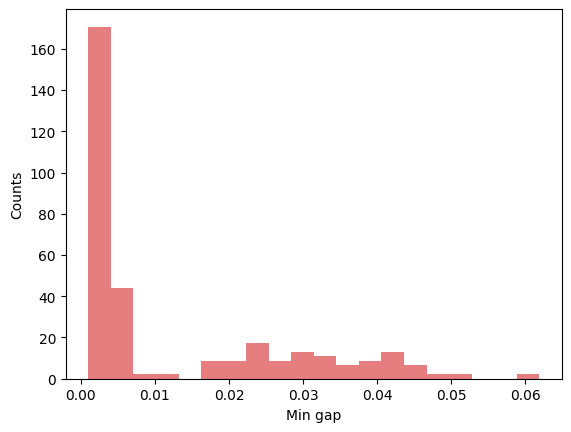

{'samples': [{'min_gap': 0.020656964490886873, 'prob': 0.9124609242211591}, {'min_gap': 0.021357096364007774, 'prob': 0.8634574884475589}, {'min_gap': 0.015126702926598706, 'prob': 0.6461956570644816}, {'min_gap': 0.010212111792388054, 'prob': 0.5686866470450624}, {'min_gap': 0.019846500268186545, 'prob': 0.8428498622348881}, {'min_gap': 0.019194696858977636, 'prob': 0.9304739465973155}, {'min_gap': 0.022522625603479146, 'prob': 0.8842980236429491}, {'min_gap': 0.016595369446994135, 'prob': 0.7965820829497976}, {'min_gap': 0.008104187767656784, 'prob': 0.4591747246333294}, {'min_gap': 0.016671683914146626, 'prob': 0.6426198620643406}, {'min_gap': 0.019887263883011957, 'prob': 0.8778942121013403}, {'min_gap': 0.018294174934871163, 'prob': 0.9283382432094771}, {'min_gap': 0.009557454715820743, 'prob': 0.4909481914057024}, {'min_gap': 0.02690065874006632, 'prob': 0.9409836508607938}, {'min_gap': 0.02939855059277323, 'prob': 0.9650094158771976}, {'min_gap': 0.019797478191338938, 'prob': 0.

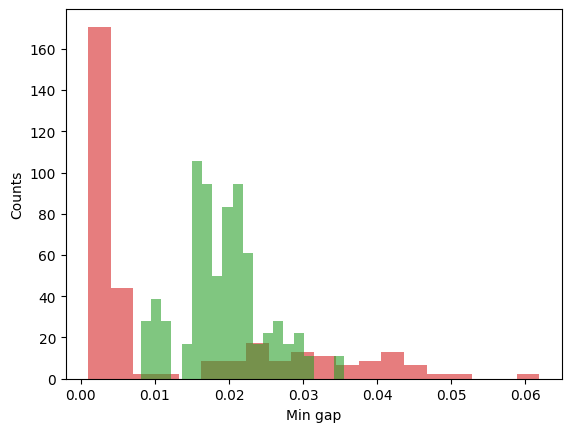

{'samples': [{'min_gap': 0.011818647069433336, 'prob': 0.9653853899186644}, {'min_gap': 0.012192340601551006, 'prob': 0.9759740318238072}, {'min_gap': 0.009039803620125533, 'prob': 0.9107306330414254}, {'min_gap': 0.010290465302992567, 'prob': 0.9488540627668791}, {'min_gap': 0.007475964782909746, 'prob': 0.8774348821615358}, {'min_gap': 0.004818098084223291, 'prob': 0.7048247494725263}, {'min_gap': 0.008506226045215871, 'prob': 0.9484222854506261}, {'min_gap': 0.0053372968206894175, 'prob': 0.574374603959519}, {'min_gap': 0.005644355732472774, 'prob': 0.7476075642659105}, {'min_gap': 0.008787283108755393, 'prob': 0.9116908468700327}, {'min_gap': 0.010896765972979887, 'prob': 0.948600439632266}, {'min_gap': 0.013858779672573956, 'prob': 0.9670455849627335}, {'min_gap': 0.012405874846308479, 'prob': 0.9797339484354382}, {'min_gap': 0.0107805123581231, 'prob': 0.9548753525186083}, {'min_gap': 0.01428360194103246, 'prob': 0.9638906443772768}, {'min_gap': 0.010422788545910049, 'prob': 0.93

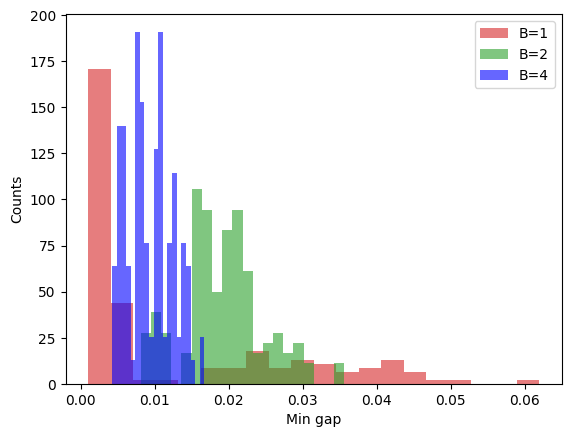

In [20]:
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_B1.json", plot="gap hist", color="tab:red", label="B=1")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_B2.json", plot="gap hist", fig=fig, color="tab:green", label="B=2")
fig = plot_annealing("benchmarkResults/energies/qa_energies_results_maxclique_B4.json", plot="gap hist", fig=fig, color="blue", label="B=4", legend=True)

{'samples': [{'min_gap': 0.02811691730287058, 'prob': 0.7265393374471156}, {'min_gap': 0.0017185042050166244, 'prob': 0.5049502210226466}, {'min_gap': 0.0010761792116373153, 'prob': 0.6147751153397926}, {'min_gap': 0.001448760629147755, 'prob': 0.5464549826620322}, {'min_gap': 0.02808498178066038, 'prob': 0.7729128657928607}, {'min_gap': 0.0011565897814091175, 'prob': 0.5875235445062031}, {'min_gap': 0.03215228648570137, 'prob': 0.7948213330465392}, {'min_gap': 0.0016220109310327024, 'prob': 0.6217023683309058}, {'min_gap': 0.0015819918965547242, 'prob': 0.6950573642375828}, {'min_gap': 0.0014423773810322421, 'prob': 0.504164466300075}, {'min_gap': 0.0018925870457202065, 'prob': 0.5687831441997508}, {'min_gap': 0.018364501719587145, 'prob': 0.5398354673668109}, {'min_gap': 0.0016100622805219067, 'prob': 0.591482529849624}, {'min_gap': 0.0013135286188687145, 'prob': 0.5818481593209954}, {'min_gap': 0.03520684636276744, 'prob': 0.7366278430787956}, {'min_gap': 0.0156793062012094, 'prob':

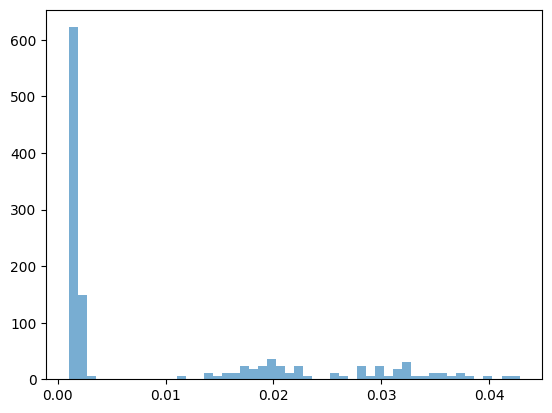

{'samples': [{'min_gap': 0.01251821742967842, 'prob': 0.8057842799884898}, {'min_gap': 0.013073663741343628, 'prob': 0.6990215254643467}, {'min_gap': 0.013183135169280144, 'prob': 0.7424822861159751}, {'min_gap': 0.019074785172535462, 'prob': 0.9408273326323059}, {'min_gap': 0.005292691988669033, 'prob': 0.4013129750020995}, {'min_gap': 0.015229198668843442, 'prob': 0.8869101630349892}, {'min_gap': 0.011449972790117065, 'prob': 0.7498611404613144}, {'min_gap': 0.015010001195821755, 'prob': 0.8772649089827512}, {'min_gap': 0.01664192225182808, 'prob': 0.9108524154747819}, {'min_gap': 0.012922025435942956, 'prob': 0.6970976519201246}, {'min_gap': 0.013366203788364669, 'prob': 0.90287778595509}, {'min_gap': 0.01914565287092847, 'prob': 0.9362561113780605}, {'min_gap': 0.017980673266224045, 'prob': 0.8691302201519175}, {'min_gap': 0.02853355818003711, 'prob': 0.9511972258584656}, {'min_gap': 0.014738556049287239, 'prob': 0.8290989476270493}, {'min_gap': 0.030329776933886325, 'prob': 0.9428

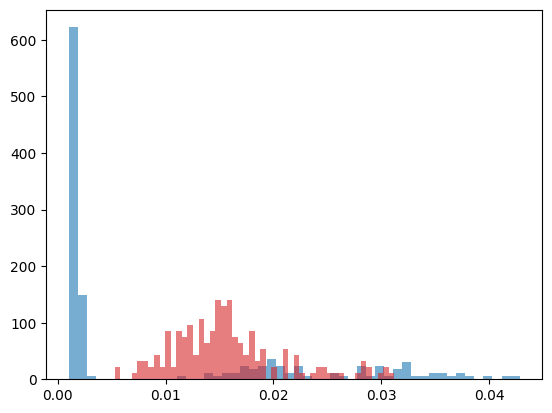

In [118]:
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_maxclique_linear.json", plot="gap hist", color="tab:blue", bins=50)
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_kclique_linear.json", plot="gap hist", fig=fig, color="tab:red", bins=50)

{'samples': [{'min_gap': 0.02811691730287058, 'prob': 0.7265393374471156}, {'min_gap': 0.0017185042050166244, 'prob': 0.5049502210226466}, {'min_gap': 0.0010761792116373153, 'prob': 0.6147751153397926}, {'min_gap': 0.001448760629147755, 'prob': 0.5464549826620322}, {'min_gap': 0.02808498178066038, 'prob': 0.7729128657928607}, {'min_gap': 0.0011565897814091175, 'prob': 0.5875235445062031}, {'min_gap': 0.03215228648570137, 'prob': 0.7948213330465392}, {'min_gap': 0.0016220109310327024, 'prob': 0.6217023683309058}, {'min_gap': 0.0015819918965547242, 'prob': 0.6950573642375828}, {'min_gap': 0.0014423773810322421, 'prob': 0.504164466300075}, {'min_gap': 0.0018925870457202065, 'prob': 0.5687831441997508}, {'min_gap': 0.018364501719587145, 'prob': 0.5398354673668109}, {'min_gap': 0.0016100622805219067, 'prob': 0.591482529849624}, {'min_gap': 0.0013135286188687145, 'prob': 0.5818481593209954}, {'min_gap': 0.03520684636276744, 'prob': 0.7366278430787956}, {'min_gap': 0.0156793062012094, 'prob':

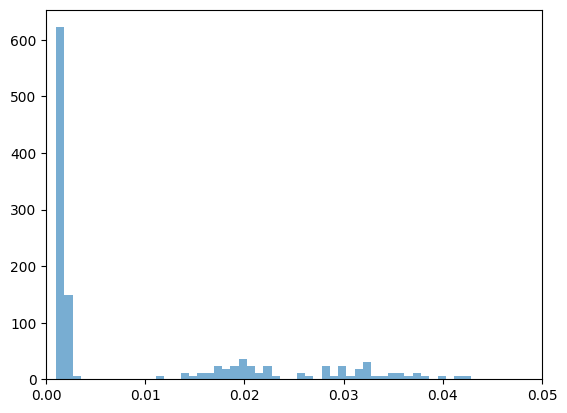

{'samples': [{'min_gap': 0.001774020251035624, 'prob': 0.6862169233129904}, {'min_gap': 0.041847953829306284, 'prob': 0.8201185024555994}, {'min_gap': 0.0019601752054769217, 'prob': 0.6770363883729266}, {'min_gap': 0.03515269682963493, 'prob': 0.8231357444202761}, {'min_gap': 0.031058198005061793, 'prob': 0.8937327237891866}, {'min_gap': 0.02534677655545292, 'prob': 0.8301219549994014}, {'min_gap': 0.0015232214553153878, 'prob': 0.6577349613037056}, {'min_gap': 0.0015055898989316252, 'prob': 0.5034713264019101}, {'min_gap': 0.001784074120026985, 'prob': 0.6225357566192421}, {'min_gap': 0.03851279604271465, 'prob': 0.8673100732609669}, {'min_gap': 0.0014627861575414736, 'prob': 0.7379935176764938}, {'min_gap': 0.0016406821771231678, 'prob': 0.6006307208357275}, {'min_gap': 0.05206882357395176, 'prob': 0.7739638948461084}, {'min_gap': 0.0014183968093533228, 'prob': 0.7588124915273898}, {'min_gap': 0.0015253326024461111, 'prob': 0.6570714619088001}, {'min_gap': 0.0015388899002194423, 'pro

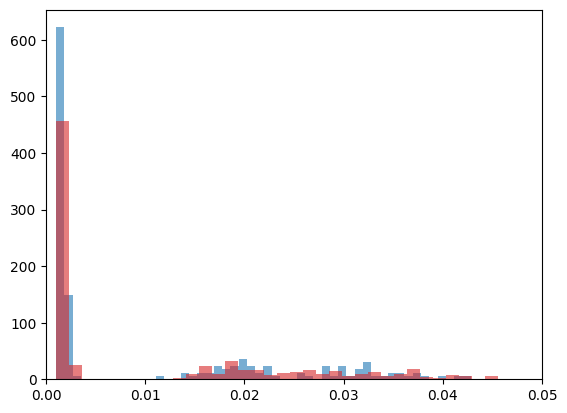

{'samples': [{'min_gap': 0.00829907631511878, 'prob': 0.5705197384756959}, {'min_gap': 0.005310196339337311, 'prob': 0.6968415708827376}, {'min_gap': 0.028828676590668817, 'prob': 0.9005047709453508}, {'min_gap': 0.0011303973766970676, 'prob': 0.5679647091105908}, {'min_gap': 0.0010123802083155664, 'prob': 0.60365928430627}, {'min_gap': 0.0010254285245581418, 'prob': 0.4188587961473421}, {'min_gap': 0.0076942375818634945, 'prob': 0.6208582909825773}, {'min_gap': 0.03656408456773602, 'prob': 0.941203464436331}, {'min_gap': 0.033122539509804455, 'prob': 0.7642650854493765}, {'min_gap': 0.0010450313393023103, 'prob': 0.5780051990849722}, {'min_gap': 0.007684940605218654, 'prob': 0.6958871326517617}, {'min_gap': 0.007694239810548176, 'prob': 0.6151759290538485}, {'min_gap': 0.04214453161423043, 'prob': 0.9294933956920423}, {'min_gap': 0.008307728153518656, 'prob': 0.6113459830117602}, {'min_gap': 0.023294757320794668, 'prob': 0.8077793099371706}, {'min_gap': 0.0010444455268995012, 'prob': 

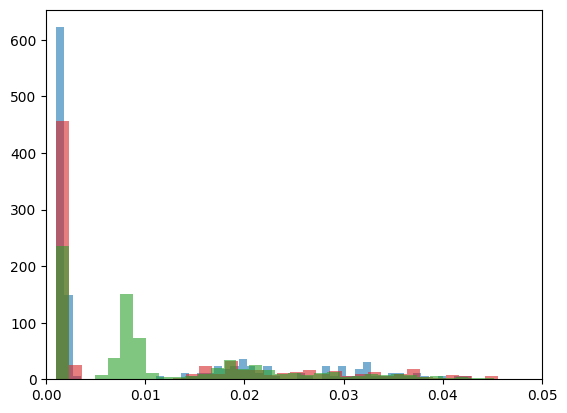

In [120]:
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_maxclique_linear.json", plot="gap hist", color="tab:blue", bins=50, xlim=(0, 0.05))
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_maxclique_boquadratic.json", plot="gap hist", fig=fig, color="tab:red", bins=50)
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_maxclique_lininterp.json", plot="gap hist", fig=fig, color="tab:green", bins=50)

{'samples': [{'min_gap': 0.011002409324720415, 'prob': 0.6148580975422449}, {'min_gap': 0.0144186290090851, 'prob': 0.8105254204712917}, {'min_gap': 0.01953234969117794, 'prob': 0.8812334079063026}, {'min_gap': 0.01722704517433725, 'prob': 0.8769235609882731}, {'min_gap': 0.014750995215237048, 'prob': 0.9175655912818267}, {'min_gap': 0.015068060628725542, 'prob': 0.8522029265351045}, {'min_gap': 0.008331968317385783, 'prob': 0.7346867458100759}, {'min_gap': 0.008503091001507809, 'prob': 0.7234633468669639}, {'min_gap': 0.012839229917742861, 'prob': 0.9144103608023324}, {'min_gap': 0.009757873430939389, 'prob': 0.765865561763086}, {'min_gap': 0.014705808313932017, 'prob': 0.8480838334878804}, {'min_gap': 0.020047156872034316, 'prob': 0.956255961181216}, {'min_gap': 0.01587307361651321, 'prob': 0.9607040993493571}, {'min_gap': 0.02704196436191707, 'prob': 0.9742159813073734}, {'min_gap': 0.018523821358607934, 'prob': 0.8994307610169898}, {'min_gap': 0.011096984545353782, 'prob': 0.804338

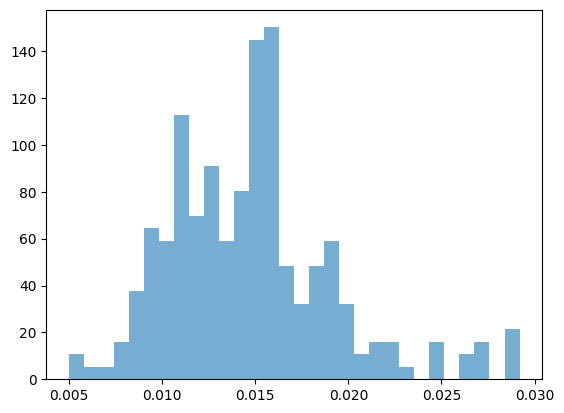

{'samples': [{'min_gap': 0.01251821742967842, 'prob': 0.8057842799884898}, {'min_gap': 0.013073663741343628, 'prob': 0.6990215254643467}, {'min_gap': 0.013183135169280144, 'prob': 0.7424822861159751}, {'min_gap': 0.019074785172535462, 'prob': 0.9408273326323059}, {'min_gap': 0.005292691988669033, 'prob': 0.4013129750020995}, {'min_gap': 0.015229198668843442, 'prob': 0.8869101630349892}, {'min_gap': 0.011449972790117065, 'prob': 0.7498611404613144}, {'min_gap': 0.015010001195821755, 'prob': 0.8772649089827512}, {'min_gap': 0.01664192225182808, 'prob': 0.9108524154747819}, {'min_gap': 0.012922025435942956, 'prob': 0.6970976519201246}, {'min_gap': 0.013366203788364669, 'prob': 0.90287778595509}, {'min_gap': 0.01914565287092847, 'prob': 0.9362561113780605}, {'min_gap': 0.017980673266224045, 'prob': 0.8691302201519175}, {'min_gap': 0.02853355818003711, 'prob': 0.9511972258584656}, {'min_gap': 0.014738556049287239, 'prob': 0.8290989476270493}, {'min_gap': 0.030329776933886325, 'prob': 0.9428

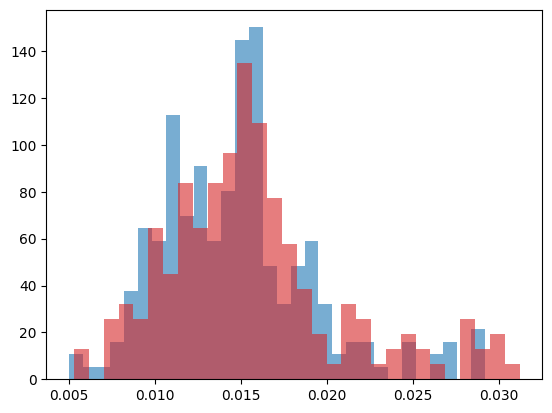

In [76]:
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_kclique_boquadratic.json", plot="gap hist", color="tab:blue", bins=30)
fig = plot_annealing("benchmarkResults/min_gap/qa_gap_results_kclique_linear.json", plot="gap hist", fig=fig, color="tab:red", bins=30)